# How Does a Neural Network Actually Learn?
## Backpropagation & Gradient Descent, Built From Scratch

**CIS 4020 · Assignment 3 · Tutorial Notebook**

*Estimated time: 25–30 minutes. No deep-learning libraries needed: we use plain Python, plus NumPy, matplotlib and scikit-learn for data and plots.*

## 1. Overview

When you call `model.fit()` on a neural network, millions of numbers get adjusted until the model works. This tutorial opens that black box. You'll learn **what a gradient is and why it tells us how to improve a model**, **how the chain rule lets us compute every gradient in one backward sweep (backpropagation)**, and **how gradient descent uses those gradients to train**. We'll build a tiny *automatic differentiation engine* (about 50 lines of Python, inspired by Andrej Karpathy's *micrograd*), use it to train a small neural network on a non-linear classification problem, and check our gradients numerically along the way. **You should already know:** Python (classes, closures), basic ML vocabulary (features, labels, loss function, train/test split), and the idea of a derivative from first-year calculus. No PyTorch or TensorFlow experience is needed. By the end, `loss.backward()` and `optimizer.step()` should no longer feel like magic.

In [1]:
# ---- Setup: imports and a fixed random seed for full reproducibility ----
import math
import random

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

SEED = 42
random.seed(SEED)      # used for neural-network weight initialisation
np.random.seed(SEED)   # used for any NumPy randomness

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print("Setup complete. Seed =", SEED)

Setup complete. Seed = 42


## 2. Motivation: walking downhill in the fog

Picture yourself on a mountainside in thick fog, trying to reach the valley floor. You can't see the valley, but **you can feel the slope under your feet**. A sensible plan is to feel which way is downhill, take a small step that way, and repeat.

Training a model works the same way:

| Mountain | Machine learning |
|---|---|
| Your position | The model's parameters (weights) |
| Your altitude | The **loss**, i.e. how wrong the model is |
| The slope under your feet | The **gradient** of the loss with respect to each parameter |
| Taking a step downhill | **Gradient descent**: nudge each parameter against its gradient |

Let's see this with the simplest possible "model": one knob $w$, predicting $\hat{y} = w \cdot x$. The true relationship in our data is $y = 2x$, so the best knob setting is $w = 2$.

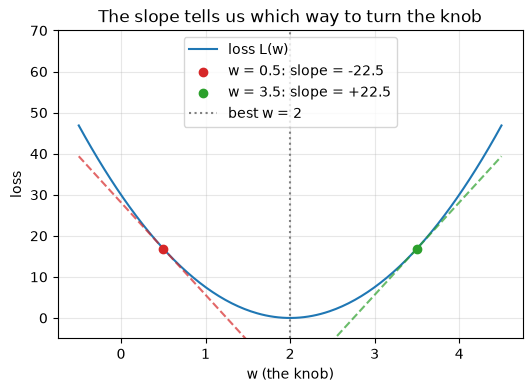

In [2]:
# A one-knob model: y_hat = w * x.  The data were generated with true w = 2.
xs_toy = [1.0, 2.0, 3.0, 4.0]
ys_toy = [2.0, 4.0, 6.0, 8.0]

def toy_loss(w):
    # Mean squared error of the one-knob model
    return sum((w * x - y) ** 2 for x, y in zip(xs_toy, ys_toy)) / len(xs_toy)

def numerical_slope(f, w, h=1e-6):
    # "Feel the slope": nudge w a tiny bit and see how much f changes
    return (f(w + h) - f(w)) / h

ws = np.linspace(-0.5, 4.5, 200)
plt.plot(ws, [toy_loss(w) for w in ws], label="loss L(w)")
for w0, colour in [(0.5, "tab:red"), (3.5, "tab:green")]:
    s = numerical_slope(toy_loss, w0)
    tangent = toy_loss(w0) + s * (ws - w0)
    plt.plot(ws, tangent, "--", color=colour, alpha=0.7)
    plt.scatter([w0], [toy_loss(w0)], color=colour, zorder=3,
                label=f"w = {w0}: slope = {s:+.1f}")
plt.axvline(2.0, color="gray", ls=":", label="best w = 2")
plt.ylim(-5, 70); plt.xlabel("w (the knob)"); plt.ylabel("loss")
plt.title("The slope tells us which way to turn the knob")
plt.legend(); plt.show()

**Notice that** the sign of the slope tells us which way to go. At $w=0.5$ the slope is **negative** (the loss falls as $w$ grows), so we should *increase* $w$. At $w=3.5$ the slope is **positive**, so we should *decrease* $w$. Either way, the rule is **step in the opposite direction of the slope**. The slope is also steeper the farther we are from the minimum, so it tells us roughly how far to go too.

**So why do we need anything more clever?** Above we "felt" the slope by nudging $w$ and re-computing the loss. That's fine for one knob. A modern network has millions or billions of knobs, and nudging each one separately means **one full forward pass per parameter, per training step**. For a 100-million-parameter model that's 100 million forward passes just to take *one* step.

**Backpropagation** solves this. It computes the slope with respect to **every** parameter at once, at a cost of roughly one forward pass plus one backward pass. It is why training deep networks is feasible at all, and it's what PyTorch's `loss.backward()` does.

## 3. The Concept

We'll build up in four steps:
1. **Derivatives** measure "nudge sensitivity".
2. **Computation graphs** break a big formula into tiny operations.
3. **The chain rule** combines local sensitivities into global ones. This *is* backpropagation.
4. **Gradient descent** uses those sensitivities to update parameters.

### 3.1 The derivative: "if I nudge the input, how much does the output move?"

The derivative of $f$ at $x$ is

$$
f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}
$$

Reading it piece by piece:
- $h$ is a tiny nudge to the input.
- $f(x+h) - f(x)$ is how much the output changed because of that nudge.
- Dividing by $h$ gives change in output **per unit** change in input, i.e. a *rate*, or sensitivity.
- $\lim_{h\to 0}$ means "make the nudge infinitesimally small" so we measure the slope exactly *at* $x$.

When a function has several inputs, e.g. $L(w_1, w_2, \dots)$, we ask the same question about each input separately while holding the others fixed. That's a **partial derivative** $\frac{\partial L}{\partial w_i}$. The list of all of them is the **gradient**, $\nabla L$.

In [3]:
def f(x):
    return 3 * x**2 - 4 * x + 5

x0 = 3.0
for h in [0.1, 0.01, 0.001, 1e-6]:
    print(f"h = {h:<8}  (f(x+h) - f(x)) / h = {(f(x0 + h) - f(x0)) / h:.6f}")
print("Exact derivative from calculus: f'(x) = 6x - 4 =", 6 * x0 - 4)

h = 0.1       (f(x+h) - f(x)) / h = 14.300000
h = 0.01      (f(x+h) - f(x)) / h = 14.030000
h = 0.001     (f(x+h) - f(x)) / h = 14.003000
h = 1e-06     (f(x+h) - f(x)) / h = 14.000003
Exact derivative from calculus: f'(x) = 6x - 4 = 14.0


**Notice that** as $h$ shrinks, the estimate converges to the exact answer, $14$. In words: *near $x=3$, increasing $x$ by a little bit increases $f$ by about 14 times that little bit.* That interpretation is all a gradient is.

We'll keep this **finite-difference** method around as a *test*. It's too slow for training, but it's a cheap way to check that a faster method gives correct answers.

### 3.2 Computation graphs: big formulas are just small steps

Any formula a computer evaluates is a chain of simple operations (`+`, `*`, `**`, `tanh`, ...). Take this tiny "model":

$$
L = (x \cdot w + b)^2 \qquad \text{with } x = 2,\; w = -3,\; b = 10
$$

We can name each intermediate result and draw it as a graph. Data flows **forward** (left → right) to compute $L$:

```
  x = 2  ──┐
           (*)──► p = x·w = -6 ──┐
  w = -3 ──┘                     (+)──► z = p + b = 4 ──► (**2) ──► L = z² = 16
  b = 10 ────────────────────────┘
```

The question backprop answers: **how sensitive is $L$ to each of $x$, $w$, $b$?**

### 3.3 The chain rule: local sensitivities multiply

Each node only "knows" its own **local derivative**, meaning how its output responds to its direct inputs:

| Operation | Local derivatives | Intuition |
|---|---|---|
| $z = p + b$ | $\frac{\partial z}{\partial p} = 1$, $\frac{\partial z}{\partial b} = 1$ | Addition **passes the gradient through unchanged** |
| $p = x \cdot w$ | $\frac{\partial p}{\partial x} = w$, $\frac{\partial p}{\partial w} = x$ | Multiplication **scales the gradient by the *other* input** |
| $L = z^2$ | $\frac{\partial L}{\partial z} = 2z$ | Power rule |

The **chain rule** says that to get the sensitivity of $L$ to some early variable, you **multiply the local sensitivities along the path**:

$$
\frac{\partial L}{\partial w} \;=\; \underbrace{\frac{\partial L}{\partial z}}_{\text{how } L \text{ reacts to } z} \cdot \underbrace{\frac{\partial z}{\partial p}}_{\text{how } z \text{ reacts to } p} \cdot \underbrace{\frac{\partial p}{\partial w}}_{\text{how } p \text{ reacts to } w} \;=\; (2z)(1)(x) = (8)(1)(2) = 16
$$

Intuition: if nudging $w$ moves $p$ by 2×, and nudging $p$ moves $z$ by 1×, and nudging $z$ moves $L$ by 8×, then nudging $w$ moves $L$ by $2 \times 1 \times 8 = 16$×. That's how gear ratios compound.

**Backpropagation** applies this rule efficiently. Start at the output with $\frac{\partial L}{\partial L} = 1$, then walk the graph **backwards**. At each node, take the gradient that arrived from above and multiply it by the local derivative to pass it down. Each node is visited once, and every intermediate gradient is reused rather than recomputed. Let's do it by hand:

In [4]:
# Forward pass (compute values left -> right)
x, w, b = 2.0, -3.0, 10.0
p = x * w          # -6
z = p + b          #  4
L = z ** 2         # 16

# Backward pass (compute gradients right -> left), applying the chain rule
dL_dL = 1.0                     # base case: L's sensitivity to itself
dL_dz = dL_dL * (2 * z)         # power rule:      8
dL_dp = dL_dz * 1.0             # '+' passes it:   8
dL_db = dL_dz * 1.0             # '+' passes it:   8
dL_dx = dL_dp * w               # '*' uses other: -24
dL_dw = dL_dp * x               # '*' uses other:  16

print(f"Backprop by hand:  dL/dx = {dL_dx}, dL/dw = {dL_dw}, dL/db = {dL_db}")

# Check against finite differences (nudge each input, re-run the forward pass)
def L_of(x, w, b):
    return (x * w + b) ** 2
h = 1e-6
print(f"Finite difference: dL/dx = {(L_of(x+h, w, b) - L_of(x, w, b))/h:.3f}, "
      f"dL/dw = {(L_of(x, w+h, b) - L_of(x, w, b))/h:.3f}, "
      f"dL/db = {(L_of(x, w, b+h) - L_of(x, w, b))/h:.3f}")

Backprop by hand:  dL/dx = -24.0, dL/dw = 16.0, dL/db = 8.0
Finite difference: dL/dx = -24.000, dL/dw = 16.000, dL/db = 8.000


**Notice that** the two methods agree. Also read the signs as advice: $\frac{\partial L}{\partial w} = +16$ means *increasing* $w$ increases the loss, so to reduce $L$ we should **decrease** $w$. Meanwhile $\frac{\partial L}{\partial x} = -24$ means $L$ is most sensitive to $x$. In a real model $x$ is data and we can't change it, but the gradient still tells us how the output would react.

### 3.4 Automating it: a tiny autograd engine

Doing this by hand for a network with hundreds of operations would be miserable. Instead we'll make every number **remember how it was created**. We define a `Value` class that wraps a float and stores:

- `data`: the number itself (computed in the forward pass)
- `grad`: $\frac{\partial L}{\partial \text{this value}}$ (filled in by the backward pass, starts at 0)
- `_prev`: the values it was computed from (its parents in the graph)
- `_backward`: a small function that knows the **local derivative** of the operation that produced it, and pushes gradient to its parents

Then `backward()` sorts the graph so every node comes after its inputs (a **topological sort**), and calls each node's `_backward` in **reverse** order. That ordering guarantees a node has received *all* of its gradient before it passes gradient further back.

In [5]:
class Value:
    # A scalar that records the computation graph and supports backprop.

    def __init__(self, data, _children=(), _op="", label=""):
        self.data = float(data)
        self.grad = 0.0                  # dL/d(self); filled in by backward()
        self._backward = lambda: None    # leaf nodes have nothing to propagate
        self._prev = tuple(_children)    # the Values this one was computed from
        self._op = _op                   # which operation produced it (for display)
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

    # ---------- core operations: each defines forward AND local backward ----------
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            # d(out)/d(self) = 1, d(out)/d(other) = 1  ->  pass gradient through
            self.grad  += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            # d(out)/d(self) = other, d(out)/d(other) = self  ->  "swap" and scale
            self.grad  += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, k):
        assert isinstance(k, (int, float)), "only constant powers supported"
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad   # power rule
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t ** 2) * out.grad               # d tanh(x)/dx = 1 - tanh(x)^2
        out._backward = _backward
        return out

    # ---------- conveniences built from the core ops (no new calculus needed) ----------
    def __neg__(self):             return self * -1
    def __sub__(self, other):      return self + (-other)
    def __rsub__(self, other):     return (-self) + other
    def __radd__(self, other):     return self + other      # lets sum() and 3 + v work
    def __rmul__(self, other):     return self * other      # lets 3 * v work
    def __truediv__(self, other):  return self * other ** -1
    def __rtruediv__(self, other): return other * self ** -1

    # ---------- backpropagation ----------
    def backward(self):
        # 1) Topological order: every node appears after all of its inputs.
        topo, visited = [], set()
        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                topo.append(v)
        build(self)
        # 2) Seed dL/dL = 1, then apply the chain rule from the output backwards.
        self.grad = 1.0
        for v in reversed(topo):
            v._backward()

print("Value class defined.")

Value class defined.


Two design choices matter a lot here. We come back to both in the pitfalls section:
- Gradients are **accumulated with `+=`**, never assigned with `=`. A value used in several places must collect gradient from *all* of them. (This is the multivariable chain rule: contributions along different paths **add up**.)
- `backward()` **does not reset** old gradients, so we must zero them ourselves before each training step.

Now let's re-run the hand-worked example, this time letting the engine do the backward pass:

In [6]:
def show_graph(v, depth=0):
    # Print the computation graph as an indented tree (output at the top).
    name = v.label or v._op
    print("    " * depth + f"{name:>5} | data = {v.data:7.2f} | grad = {v.grad:7.2f}")
    for child in v._prev:
        show_graph(child, depth + 1)

x = Value(2.0, label="x"); w = Value(-3.0, label="w"); b = Value(10.0, label="b")
p = x * w;   p.label = "p"
z = p + b;   z.label = "z"
L = z ** 2;  L.label = "L"

L.backward()
show_graph(L)

    L | data =   16.00 | grad =    1.00
        z | data =    4.00 | grad =    8.00
            p | data =   -6.00 | grad =    8.00
                x | data =    2.00 | grad =  -24.00
                w | data =   -3.00 | grad =   16.00
            b | data =   10.00 | grad =    8.00


**Notice that** the engine reproduces our hand calculation exactly ($\partial L/\partial x = -24$, $\partial L/\partial w = 16$, $\partial L/\partial b = 8$), and we wrote no derivative code for this specific formula. Each operation only knows its own local rule. The engine composes them.

### 3.5 Gradient descent: turning gradients into learning

Once we have the gradient, the update rule for every parameter $\theta$ is

$$
\theta \;\leftarrow\; \theta - \eta \, \frac{\partial L}{\partial \theta}
$$

- $\frac{\partial L}{\partial \theta}$ points in the direction that **increases** the loss fastest (uphill).
- The **minus sign** means we step **downhill**.
- $\eta$ (eta), the **learning rate**, is the step size. Too small and training crawls. Too large and we overshoot the valley and can diverge (we'll see this happen in §5).

So a full training step is: **forward pass → compute loss → zero gradients → backward pass → update**. Let's run it on the one-knob model from §2, starting from a bad guess of $w = 0.5$:

In [7]:
w = Value(0.5)
lr = 0.05
for step in range(8):
    loss = sum((w * x - y) ** 2 for x, y in zip(xs_toy, ys_toy)) / len(xs_toy)  # forward
    w.grad = 0.0                                                               # zero grad
    loss.backward()                                                            # backward
    print(f"step {step}: w = {w.data:.4f}   loss = {loss.data:8.4f}   dL/dw = {w.grad:+8.4f}")
    w.data -= lr * w.grad                                                      # update
print(f"final w = {w.data:.4f}  (true value 2.0)")

step 0: w = 0.5000   loss =  16.8750   dL/dw = -22.5000
step 1: w = 1.6250   loss =   1.0547   dL/dw =  -5.6250
step 2: w = 1.9062   loss =   0.0659   dL/dw =  -1.4062
step 3: w = 1.9766   loss =   0.0041   dL/dw =  -0.3516
step 4: w = 1.9941   loss =   0.0003   dL/dw =  -0.0879
step 5: w = 1.9985   loss =   0.0000   dL/dw =  -0.0220
step 6: w = 1.9996   loss =   0.0000   dL/dw =  -0.0055
step 7: w = 1.9999   loss =   0.0000   dL/dw =  -0.0014
final w = 2.0000  (true value 2.0)


**Notice that** the gradient starts large and negative (we're far left of the minimum, so $w$ should go up), then shrinks toward zero as $w$ approaches 2. The steps automatically get smaller as we near the bottom, even with a fixed learning rate, because the slope flattens out.

That's the whole algorithm. A neural network is the same thing with a much bigger graph.

## 4. Worked Example: training a neural network from scratch

**Task:** classify points from scikit-learn's `make_moons` dataset. It has two interleaving half-circles, so no straight line can separate them, and a linear model like logistic regression will fail. A neural network has to *learn* a curved decision boundary.

### 4.1 The data

Train: (100, 2)  Test: (300, 2)  Labels: [-1, 1]


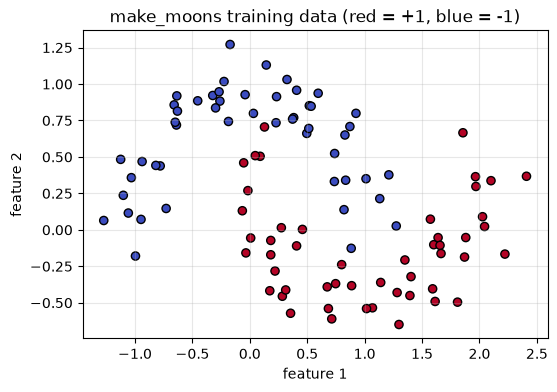

In [7]:
X_train, y_train = make_moons(n_samples=100, noise=0.15, random_state=SEED)
X_test,  y_test  = make_moons(n_samples=300, noise=0.15, random_state=SEED + 1)  # fresh, unseen points

# Use labels -1 / +1 so they match the range of tanh, our output activation
y_train = 2 * y_train - 1
y_test  = 2 * y_test - 1

print("Train:", X_train.shape, " Test:", X_test.shape, " Labels:", sorted(set(y_train.tolist())))

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolors="k", s=35)
plt.title("make_moons training data (red = +1, blue = -1)")
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.show()

### 4.2 Building a neural network out of `Value`s

A **neuron** computes a weighted sum of its inputs plus a bias, then squashes it through a non-linear **activation** function:

$$
\text{out} = \tanh\Big(\sum_i w_i x_i + b\Big)
$$

- $w_i$ (**weights**) say how much each input matters, and $b$ (**bias**) shifts the threshold. These are the knobs we'll learn.
- $\tanh$ squashes any number into $(-1, 1)$. The non-linearity is what lets stacked layers represent curves. Without it, any number of layers would collapse into one linear function.

A **layer** is several neurons looking at the same inputs, and an **MLP** (multi-layer perceptron) is layers chained together. Every operation inside is a `Value` operation, so the whole network automatically becomes one big computation graph that `backward()` can differentiate.

In [9]:
class Neuron:
    def __init__(self, n_inputs):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(n_inputs)]
        self.b = Value(0.0)

    def __call__(self, x):
        # weighted sum + bias, then tanh activation
        activation = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return activation.tanh()

    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self, n_inputs, n_outputs):
        self.neurons = [Neuron(n_inputs) for _ in range(n_outputs)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]


class MLP:
    def __init__(self, n_inputs, layer_sizes):
        sizes = [n_inputs] + layer_sizes
        self.layers = [Layer(sizes[i], sizes[i + 1]) for i in range(len(layer_sizes))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def zero_grad(self):
        for p in self.parameters():
            p.grad = 0.0


random.seed(SEED)                     # re-seed so the initial weights are reproducible
model = MLP(2, [16, 16, 1])           # 2 inputs -> 16 hidden -> 16 hidden -> 1 output
print("Number of trainable parameters:", len(model.parameters()))

Number of trainable parameters: 337


That's $2 \cdot 16 + 16$ (layer 1) $+\; 16 \cdot 16 + 16$ (layer 2) $+\; 16 + 1$ (output) $= 337$ knobs. Finite differences would need 337 extra forward passes per step. Backprop needs one backward pass.

### 4.3 The loss function

We'll use **mean squared error** between the network's output (a number in $(-1,1)$) and the label ($-1$ or $+1$):

$$
L = \frac{1}{N}\sum_{n=1}^{N} \big(\hat{y}_n - y_n\big)^2
$$

Each term is zero when the prediction exactly matches the label and grows as it drifts away. We predict class $+1$ when $\hat{y} > 0$. (Production classifiers usually use cross-entropy loss instead. MSE keeps our engine small, and the backprop mechanics are identical.)

### 4.4 Before training: check the gradients!

Never trust a hand-written backward pass until you've tested it. We'll compare backprop's gradient for a few parameters against the finite-difference estimate from §3.1:

In [10]:
def compute_loss(model, X, y):
    preds = [model(list(xi)) for xi in X]
    loss = sum((p - yi) ** 2 for p, yi in zip(preds, y)) / len(y)
    return loss, preds

# Backprop gradients
model.zero_grad()
loss, _ = compute_loss(model, X_train, y_train)
loss.backward()

# Finite-difference gradients for a handful of parameters
params = model.parameters()
h = 1e-5
print(f"{'param':>6} | {'backprop':>12} | {'finite diff':>12} | {'abs diff':>9}")
for idx in [0, 1, 50, 200, 336]:
    p = params[idx]
    original = p.data
    p.data = original + h
    loss_plus, _ = compute_loss(model, X_train, y_train)
    p.data = original - h
    loss_minus, _ = compute_loss(model, X_train, y_train)
    p.data = original                                       # restore!
    fd = (loss_plus.data - loss_minus.data) / (2 * h)       # centred difference (more accurate)
    print(f"{idx:>6} | {p.grad:>12.8f} | {fd:>12.8f} | {abs(p.grad - fd):>9.2e}")

 param |     backprop |  finite diff |  abs diff
     0 |  -0.00907039 |  -0.00907039 |  5.79e-12
     1 |   0.00376880 |   0.00376880 |  6.54e-12
    50 |   0.00059647 |   0.00059647 |  6.59e-12
   200 |  -0.00798364 |  -0.00798364 |  3.51e-12
   336 |   0.10773493 |   0.10773493 |  1.53e-11


**Notice that** the two columns agree on every printed digit (the differences are around $10^{-11}$). That's convincing evidence the engine is correct. (We used a *centred* difference, $\frac{f(x+h)-f(x-h)}{2h}$, whose error shrinks like $h^2$ instead of $h$.) Notice also that each finite-difference check needed **two full passes over the dataset for a single parameter**. Backprop got all 337 gradients from one backward pass.

### 4.5 The training loop

In [11]:
def accuracy(preds, y):
    return np.mean([(p.data > 0) == (yi > 0) for p, yi in zip(preds, y)])

learning_rate = 0.1
n_steps = 150
history = {"loss": [], "acc": []}

for step in range(n_steps):
    # 1. forward pass + loss
    loss, preds = compute_loss(model, X_train, y_train)
    # 2. zero old gradients, 3. backward pass
    model.zero_grad()
    loss.backward()
    # 4. gradient descent update
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    history["loss"].append(loss.data)
    history["acc"].append(accuracy(preds, y_train))
    if step % 25 == 0 or step == n_steps - 1:
        print(f"step {step:3d} | loss = {loss.data:.4f} | train accuracy = {history['acc'][-1]:.0%}")

step   0 | loss = 0.6068 | train accuracy = 81%
step  25 | loss = 0.2448 | train accuracy = 91%
step  50 | loss = 0.1798 | train accuracy = 95%
step  75 | loss = 0.1416 | train accuracy = 97%
step 100 | loss = 0.1159 | train accuracy = 97%
step 125 | loss = 0.0979 | train accuracy = 97%
step 149 | loss = 0.0854 | train accuracy = 97%


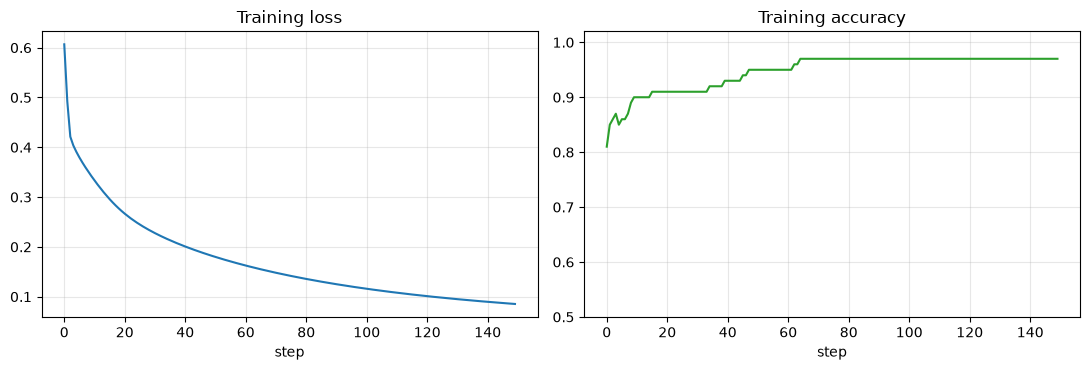

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(history["loss"]); axes[0].set_title("Training loss"); axes[0].set_xlabel("step")
axes[1].plot(history["acc"], color="tab:green"); axes[1].set_title("Training accuracy")
axes[1].set_xlabel("step"); axes[1].set_ylim(0.5, 1.02)
plt.tight_layout(); plt.show()

**Notice that** the loss drops steeply at first and then flattens. This is the same behaviour as the one-knob model: big gradients far from a good solution, smaller ones as we approach it. Accuracy climbs in jumps because it only changes when a point crosses the decision boundary, while the loss improves smoothly because it rewards being *more confidently* right. This is one reason we optimise the loss and not accuracy directly: accuracy is flat almost everywhere, so its gradient is zero and gives no direction to move.

### 4.6 What did the network learn?

Training accuracy alone can fool us, so let's look at the decision boundary and evaluate on the **300 unseen test points**:

Test accuracy on unseen points: 99.7%


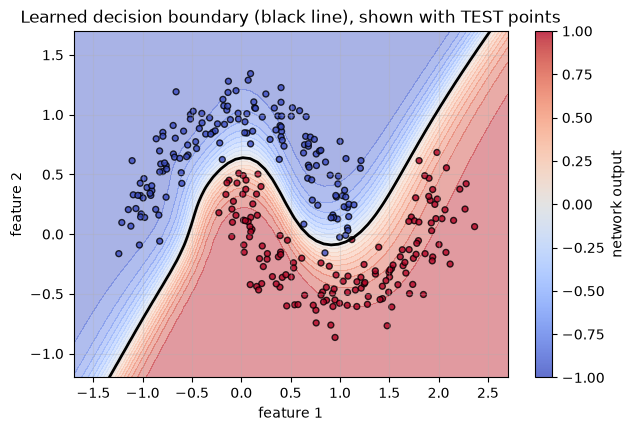

In [13]:
_, test_preds = compute_loss(model, X_test, y_test)
print(f"Test accuracy on unseen points: {accuracy(test_preds, y_test):.1%}")

# Evaluate the network on a grid to draw its decision boundary
xx, yy = np.meshgrid(np.linspace(-1.7, 2.7, 60), np.linspace(-1.2, 1.7, 60))
grid_out = np.array([model([a, b]).data for a, b in zip(xx.ravel(), yy.ravel())]).reshape(xx.shape)

plt.figure(figsize=(7, 4.5))
plt.contourf(xx, yy, grid_out, levels=20, cmap="coolwarm", alpha=0.45)
plt.contour(xx, yy, grid_out, levels=[0], colors="k", linewidths=2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", edgecolors="k", s=18, alpha=0.8)
plt.title("Learned decision boundary (black line), shown with TEST points")
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.colorbar(label="network output"); plt.show()

**Notice that** the black line (output $= 0$) is a smooth curve that snakes between the two moons. Nobody told the network to draw a curve. It emerged from 150 repetitions of *forward → backward → nudge*. The shading shows confidence: deep red and blue regions are where the output is close to $\pm1$. Points that are misclassified, if any, sit where noise pushed them into the other moon's territory, which is the region where the model is least confident.

Test accuracy is about as high as training accuracy, so the model **generalised** rather than memorised. With only 100 noisy training points and 337 parameters this isn't guaranteed, which is why we checked. (Test accuracy can even come out slightly *higher* than training accuracy. That's sampling noise: with only 100 training points, a few unluckily noisy ones change training accuracy by several percent.)

### 4.7 (Optional) Sanity check against PyTorch

Our `Value` class is a scalar version of what PyTorch does with tensors. If PyTorch is installed, this cell confirms both engines give identical gradients for the expression from §3.2. If not, it skips harmlessly.

In [14]:
try:
    import torch
    xt = torch.tensor(2.0, requires_grad=True)
    wt = torch.tensor(-3.0, requires_grad=True)
    bt = torch.tensor(10.0, requires_grad=True)
    Lt = (xt * wt + bt) ** 2
    Lt.backward()
    print(f"PyTorch:      dL/dx = {xt.grad.item()}, dL/dw = {wt.grad.item()}, dL/db = {bt.grad.item()}")
    print("Our engine:   dL/dx = -24.0, dL/dw = 16.0, dL/db = 8.0  (from section 3.4)")
except ImportError:
    print("PyTorch not installed, so skipping. (The finite-difference check in 4.4 already verifies our engine.)")

PyTorch not installed, so skipping. (The finite-difference check in 4.4 already verifies our engine.)


## 5. Common Pitfalls & Misconceptions

These are the mistakes that trip people up, both when writing training code and when reasoning about it. Each one is demonstrated so you can recognise the symptom.

### Pitfall 1: Forgetting to zero the gradients

Because gradients are accumulated with `+=`, calling `backward()` twice without resetting **adds** the new gradient on top of the old one. In PyTorch this is why every loop has `optimizer.zero_grad()`. Forget it, and each step uses the *sum of all past gradients* instead of the current one.

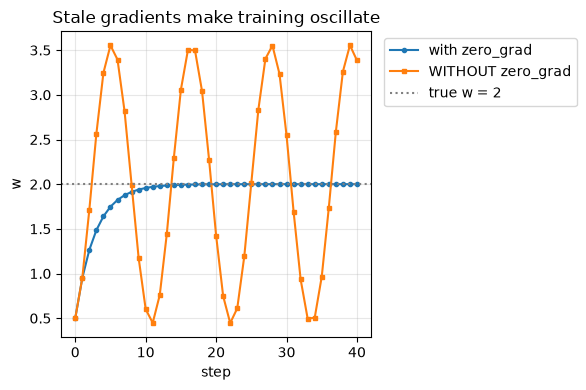

In [15]:
def train_one_knob(lr, steps, zero_grad=True):
    w = Value(0.5)
    ws = [w.data]
    for _ in range(steps):
        loss = sum((w * x - y) ** 2 for x, y in zip(xs_toy, ys_toy)) / len(xs_toy)
        if zero_grad:
            w.grad = 0.0
        loss.backward()
        w.data -= lr * w.grad
        ws.append(w.data)
    return ws

plt.plot(train_one_knob(0.02, 40, zero_grad=True),  "o-", ms=3, label="with zero_grad")
plt.plot(train_one_knob(0.02, 40, zero_grad=False), "s-", ms=3, label="WITHOUT zero_grad")
plt.axhline(2.0, color="gray", ls=":", label="true w = 2")
plt.xlabel("step"); plt.ylabel("w"); plt.title("Stale gradients make training oscillate")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Notice that** with the same learning rate, the correct version glides smoothly to $w=2$, while the buggy version overshoots and keeps oscillating. Every step it is still being pushed by gradients from long ago, when $w$ was far from 2. In a large network this bug rarely crashes anything. It just makes training mysteriously unstable or slow, which makes it hard to find.

### Pitfall 2: Overwriting gradients (`=`) instead of accumulating (`+=`)

When a value feeds into **more than one** downstream operation, its total gradient is the **sum** of the gradients arriving along each path (the multivariable chain rule). Writing `self.grad = ...` instead of `self.grad += ...` silently keeps only the *last* path's contribution. The simplest case is $b = a + a$, where $\frac{\partial b}{\partial a}$ should be $2$:

In [16]:
class BuggyValue(Value):
    # Same as Value, but addition OVERWRITES gradients instead of accumulating them.
    def __add__(self, other):
        other = other if isinstance(other, Value) else BuggyValue(other)
        out = BuggyValue(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad = out.grad     # BUG: should be +=
            other.grad = out.grad    # BUG: should be +=
        out._backward = _backward
        return out

a_bug = BuggyValue(3.0);  b_bug = a_bug + a_bug;  b_bug.backward()
a_ok  = Value(3.0);       b_ok  = a_ok + a_ok;    b_ok.backward()
print(f"b = a + a  ->  correct db/da = 2.0 | Value gives {a_ok.grad} | BuggyValue gives {a_bug.grad}")

b = a + a  ->  correct db/da = 2.0 | Value gives 2.0 | BuggyValue gives 1.0


**Why this matters far beyond a toy:** in our neural network, **every weight is reused for all 100 training examples**. With `=`, each weight's gradient would reflect only the last example processed, so you'd effectively be training on one data point per step and the code would run without any error. The gradient check in §4.4 is exactly the kind of test that catches this.

### Pitfall 3: The learning rate is too large (or too small)

The learning rate is the single most important hyperparameter in gradient descent. Here's the one-knob model with four different values:

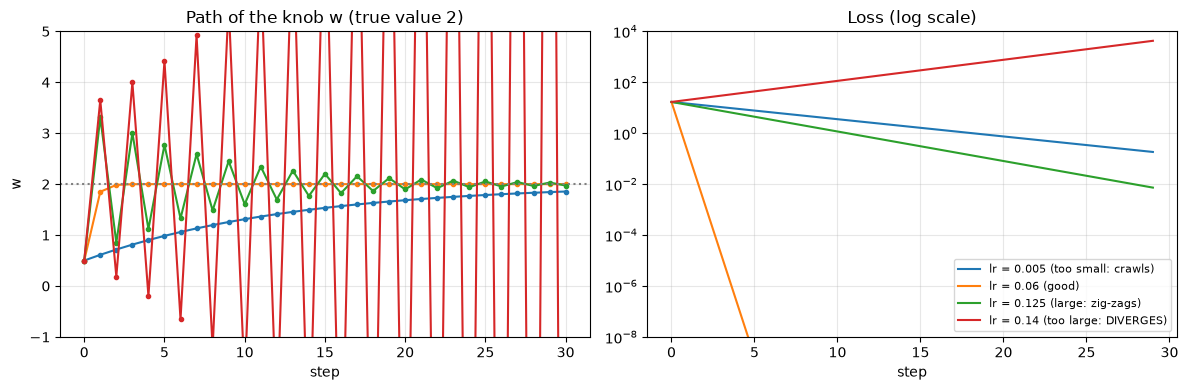

In [17]:
def run_lr(lr, steps=30):
    w = Value(0.5); ws, losses = [w.data], []
    for _ in range(steps):
        loss = sum((w * x - y) ** 2 for x, y in zip(xs_toy, ys_toy)) / len(xs_toy)
        w.grad = 0.0; loss.backward(); w.data -= lr * w.grad
        losses.append(loss.data); ws.append(w.data)
    return ws, losses

fig, (ax_w, ax_l) = plt.subplots(1, 2, figsize=(12, 4))
for lr, desc in [(0.005, "too small: crawls"), (0.06, "good"),
                 (0.125, "large: zig-zags"), (0.14, "too large: DIVERGES")]:
    ws_lr, losses_lr = run_lr(lr)
    ax_w.plot(ws_lr, ".-", label=f"lr = {lr} ({desc})")
    ax_l.semilogy(losses_lr, label=f"lr = {lr} ({desc})")
ax_w.axhline(2.0, color="gray", ls=":"); ax_w.set_ylim(-1, 5)
ax_w.set_title("Path of the knob w (true value 2)"); ax_w.set_xlabel("step"); ax_w.set_ylabel("w")
ax_l.set_ylim(1e-8, 1e4); ax_l.set_title("Loss (log scale)"); ax_l.set_xlabel("step")
ax_l.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Notice that** the left panel shows *why* the curves differ. With $\eta = 0.125$, $w$ jumps back and forth across the minimum on every step, so it closes in only slowly, and in the end it is no faster than the tiny learning rate. A learning rate only slightly larger ($0.14$) makes the zig-zags **grow**, and the loss explodes. For this quadratic loss we can see exactly why: the gradient is $15(w-2)$, so each update multiplies the error $(w-2)$ by $(1 - 15\eta)$. If $|1 - 15\eta| > 1$, i.e. $\eta > 2/15 \approx 0.133$, every step overshoots by *more* than the previous error. Real networks have the same cliff, but you can't compute where it is in advance. That's why practitioners try learning rates on a log scale (0.001, 0.01, 0.1, ...) and watch the loss curve. **A loss that goes up or becomes `nan` is the classic symptom of a learning rate that's too high.**

### Pitfall 4: Saturated activations kill gradients ("vanishing gradients")

The local derivative of $\tanh$ is $1 - \tanh(x)^2$. When the input is large in magnitude, $\tanh$ is flat (stuck near $\pm1$), so its derivative is nearly **zero**, and by the chain rule everything upstream gets multiplied by nearly zero.

In [18]:
for inp in [0.5, 2.0, 5.0, 10.0]:
    v = Value(inp); out = v.tanh(); out.backward()
    print(f"tanh({inp:>4}) = {out.data:.6f}   local gradient = {v.grad:.2e}")

tanh( 0.5) = 0.462117   local gradient = 7.86e-01
tanh( 2.0) = 0.964028   local gradient = 7.07e-02
tanh( 5.0) = 0.999909   local gradient = 1.82e-04
tanh(10.0) = 1.000000   local gradient = 8.24e-09


**Notice that** at an input of 10 the gradient is around $10^{-8}$. A neuron stuck there effectively **stops learning**, because its weights receive almost no update signal. Stack several saturated layers and the product of tiny numbers vanishes entirely. Practical consequences:
- **Scale your input features** (e.g. `StandardScaler`). Raw features in the thousands push neurons straight into saturation. Our moons data is already in roughly $[-1, 2]$, which is one reason training went smoothly.
- **Initialise weights small.** We used `uniform(-1, 1)`. Large initial weights saturate neurons before training even starts.
- This is a big reason modern networks use **ReLU** activations and careful initialisation schemes, as discussed in the Goodfellow et al. reference.

### Misconception 5: "Backpropagation is the learning algorithm"

Not quite, and the distinction matters. **Backpropagation only computes gradients**: it answers "which direction is downhill?" **Gradient descent (or Adam, RMSProp, ...) is the optimiser** that decides how to step using those gradients. They are separate stages, which is why PyTorch splits them into `loss.backward()` and `optimizer.step()`. You can swap the optimiser without touching backprop, and backprop is useful outside learning entirely, e.g. computing how sensitive a financial model's output is to each input.

### Misconception 6: "The loss went down, so the model is good"

Training loss measures how well the model fits the data it has **already seen**. Gradient descent will happily drive training loss toward zero by memorising noise (**overfitting**), especially when there are more parameters than data points (we had 337 parameters versus 100 points!). Always evaluate on **held-out data**, as we did in §4.6. A falling training loss tells you the *optimiser* is working. Only test performance tells you the *model* is working.

## 6. Your Turn

Our engine supports `+`, `*`, `**` and `tanh`. Your job is to **teach it a new operation: the exponential function $e^x$**, and then use it to build the **sigmoid** function $\sigma(x) = \frac{1}{1 + e^{-x}}$, the activation used in logistic regression.

**Tasks:**
1. Complete the `exp` method below. You need the **forward** value and the **local derivative**. Hint: $e^x$ is famously its own derivative, and remember to *accumulate* the gradient, scaled by `out.grad`.
2. Run the check cell. It verifies your gradient against finite differences.
3. **Bonus (think, then check):** build `sigmoid` using only existing operations plus your `exp`. Calculus says $\sigma'(x) = \sigma(x)\,(1-\sigma(x))$. Does your engine agree, *even though you never wrote that formula anywhere*?

Try it yourself before scrolling to the solution!

In [ ]:
# ===================== YOUR CODE HERE =====================
def exp(self):
    # TODO 1: compute the forward value and create the output node:
    #         out = Value(..., (self,), "exp")
    # TODO 2: define _backward() that adds (local derivative * out.grad) to self.grad
    # TODO 3: attach it with  out._backward = _backward  and  return out
    raise NotImplementedError("exp() is not implemented yet. Fill in the TODOs above!")

Value.exp = exp   # attach the method to the Value class
# ===========================================================

In [22]:
def check_exp():
    # Tests Value.exp against math.exp and a finite-difference gradient.
    try:
        for x0 in [-2.0, 0.0, 1.5]:
            v = Value(x0)
            out = (v * 3).exp()          # use exp inside a bigger expression
            out.backward()
            h = 1e-6
            fd = (math.exp(3 * (x0 + h)) - math.exp(3 * (x0 - h))) / (2 * h)
            assert abs(out.data - math.exp(3 * x0)) < 1e-9, "forward value is wrong"
            assert abs(v.grad - fd) < 1e-4 * max(1, abs(fd)), f"gradient wrong at x={x0}"
        print("All exp() checks passed!")
    except NotImplementedError as e:
        print("Not done yet:", e)
    except AssertionError as e:
        print("Check failed:", e)

check_exp()

All exp() checks passed!


---
### Solution (try the exercise first!)

The forward pass is `math.exp(self.data)`. Since $\frac{d}{dx}e^x = e^x$, the local derivative is just the output value itself, `out.data`, which we multiply by the incoming gradient `out.grad` (chain rule) and **accumulate** with `+=`.

In [24]:
# ======================== SOLUTION ========================
def exp(self):
    out = Value(math.exp(self.data), (self,), "exp")
    def _backward():
        self.grad += out.data * out.grad    # d(e^x)/dx = e^x, which is out.data
    out._backward = _backward
    return out

Value.exp = exp
check_exp()

# ---- Bonus: sigmoid built from existing operations ----
def sigmoid(v):
    return 1 / (1 + (-v).exp())

for x0 in [-3.0, 0.0, 2.0]:
    v = Value(x0)
    s = sigmoid(v)
    s.backward()
    analytic = s.data * (1 - s.data)
    print(f"x = {x0:+.1f}: sigmoid = {s.data:.4f} | engine grad = {v.grad:.6f} | "
          f"s(1-s) formula = {analytic:.6f}")
# ===========================================================

All exp() checks passed!
x = -3.0: sigmoid = 0.0474 | engine grad = 0.045177 | s(1-s) formula = 0.045177
x = +0.0: sigmoid = 0.5000 | engine grad = 0.250000 | s(1-s) formula = 0.250000
x = +2.0: sigmoid = 0.8808 | engine grad = 0.104994 | s(1-s) formula = 0.104994


**Notice that** the engine's gradient matches $\sigma(1-\sigma)$ exactly, though we never wrote that formula. It fell out of chaining the local rules for `neg`, `exp`, `+`, `**-1` and `*`. This is the payoff of automatic differentiation: **define new building blocks once, and gradients of anything built from them come for free.** The derivative is also largest at $x=0$ (0.25) and tiny for large $|x|$, so sigmoid saturates exactly like tanh in Pitfall 4.

## 7. Key Takeaways

- **A gradient is a sensitivity:** $\partial L/\partial w$ says how much the loss changes per unit nudge of $w$. Its sign says which direction makes things worse, so we step the other way: $\theta \leftarrow \theta - \eta\,\partial L/\partial\theta$.
- **Backpropagation is the chain rule applied backwards over a computation graph.** Each operation only needs its local derivative. Gradients flow from the output to the inputs, *multiplying* along paths and *adding* across branches. That's why `+=` and zeroing gradients both matter.
- **Backprop computes gradients; the optimiser uses them.** One backward pass gives every parameter's gradient, at roughly the cost of a forward pass, instead of one pass per parameter. This is what makes training large networks feasible.
- **Always verify gradients with finite differences** when writing custom backward code. Gradient bugs usually don't crash; they just make training quietly worse.
- **Watch the learning rate, activation saturation, and held-out performance.** A rising loss means the step size is too big, flat training can mean vanishing gradients, and low training loss alone doesn't prove the model generalises.

## 8. References

1. Karpathy, A. (2022). *The spelled-out intro to neural networks and backpropagation: building micrograd* [Video]. YouTube. https://www.youtube.com/watch?v=VMj-3S1tku0. The `Value` class design in this notebook is adapted from this lecture.
2. Karpathy, A. (2020). *micrograd: A tiny scalar-valued autograd engine and a neural net library on top of it* [Source code]. GitHub. https://github.com/karpathy/micrograd
3. Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*(6088), 533–536. https://doi.org/10.1038/323533a0
4. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*, Chapter 6.5 (Back-Propagation and Other Differentiation Algorithms) and Chapter 8 (Optimization). MIT Press. https://www.deeplearningbook.org/
5. Baydin, A. G., Pearlmutter, B. A., Radul, A. A., & Siskind, J. M. (2018). Automatic differentiation in machine learning: a survey. *Journal of Machine Learning Research, 18*(153), 1–43. https://jmlr.org/papers/v18/17-468.html
6. Nielsen, M. A. (2015). *Neural Networks and Deep Learning*, Chapter 2: How the backpropagation algorithm works. Determination Press. http://neuralnetworksanddeeplearning.com/chap2.html
7. Stanford CS231n. *Backpropagation, Intuitions* [Course notes]. https://cs231n.github.io/optimization-2/
8. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. (Used for the `make_moons` dataset.)